# Neural-LAM COSMO sample on CSCS Clariden

The lightweight reproduction of [docs/reproduce_paper_sample.md](../docs/reproduce_paper_sample.md) with
every input read from the local copies on Clariden, so nothing is downloaded except Python packages.
Runs `scripts/reproduce_paper_sample_clariden.sh` step by step: environment, datastores and graph, an
optional 1-epoch training, and the evaluation of the published checkpoint on the sample test period.

| Input | Path under `/capstor/store/cscs/swissai/ab016` |
| --- | --- |
| COSMO sample | `COSMO/cosmo_sample.zarr` |
| ERA5 boundary | `COSMO/era_subset.zarr` (2015-11 to 2020-10; the config selects the sample window) |
| Published checkpoint | `sadamov/cosmo_model.ckpt` (same file as Zenodo record 15131838) |

IFS forecasts for the sample window are not on Clariden, so the evaluation uses ERA5 boundaries
instead of IFS as in the guide.

Needs Unix group `ab016`, a Slurm account (`ab016` by default) and `uv` on `PATH`. Works with any
Jupyter kernel: the work runs in Slurm jobs and in the checkout's own venv. Without Clariden use
[reproduce_paper_sample.ipynb](reproduce_paper_sample.ipynb).

In [1]:
import os
import re
import subprocess
import time
from pathlib import Path

from IPython.display import Image, display

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("ACCOUNT", "ab016")   # Slurm account
os.environ.setdefault("PARTITION", "normal")
WORKDIR = Path(os.environ.setdefault("WORKDIR", f"/iopsstor/scratch/cscs/{os.environ['USER']}/neural_lam_sample"))
SCRIPT = "scripts/reproduce_paper_sample_clariden.sh"

def run_step(script, step):
    """Run one step of a repo script; wait for the Slurm jobs it submits and report their state."""
    # The kernel's inline matplotlib backend would leak into the jobs (sbatch exports the environment).
    env = {**os.environ, "MPLBACKEND": "Agg"}
    res = subprocess.run(["bash", script, step], cwd=REPO, capture_output=True, text=True, env=env)
    print(res.stdout, res.stderr)
    res.check_returncode()
    for job in re.findall(r"(?:Submitted batch job|->) (\d+)", res.stdout):
        while subprocess.run(["squeue", "-h", "-j", job], capture_output=True, text=True).stdout.strip():
            time.sleep(30)
        state = subprocess.run(["sacct", "-j", job, "-X", "-n", "-o", "State"],
                               capture_output=True, text=True).stdout.split()
        print(f"job {job}: {state[0] if state else 'unknown'}")
        if not state or state[0] != "COMPLETED":
            raise RuntimeError(f"job {job} did not complete, see the log above")

## 1. Environment (once)

Python 3.12, torch (CUDA), neural-lam with the `graph` extra, mllam-data-prep and weather-model-graphs at the paper tag `building-ml-lams`.

In [2]:
if not (REPO / ".venv/bin/python").exists():
    run_step(SCRIPT, "env")

## 2. Datastores and graph

Links the local inputs into `WORKDIR`, builds the mllam-data-prep datastores (interior and ERA5 boundary) and the hierarchical rectangular graph.

In [3]:
run_step(SCRIPT, "prep")

Submitted batch job 3837693
 


job 3837693: COMPLETED


## 3. Training (optional)

One epoch on the sample, only to check that the training loop runs (Step 7 of the guide). Skip it to go straight to the published checkpoint.

In [4]:
run_step(SCRIPT, "train")

Submitted batch job 3837743
 


job 3837743: COMPLETED


## 4. Evaluation of the published checkpoint

24 hourly steps with ERA5 boundaries on the sample test period; the forecasts are written to `WORKDIR/cosmo_sample_forecasts.zarr`.

In [5]:
run_step(SCRIPT, "eval")

Submitted batch job 3837799
 


job 3837799: COMPLETED


/iopsstor/scratch/cscs/sadamov/neural_lam_sample/sample_summary.png
 <stdin>:11: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.



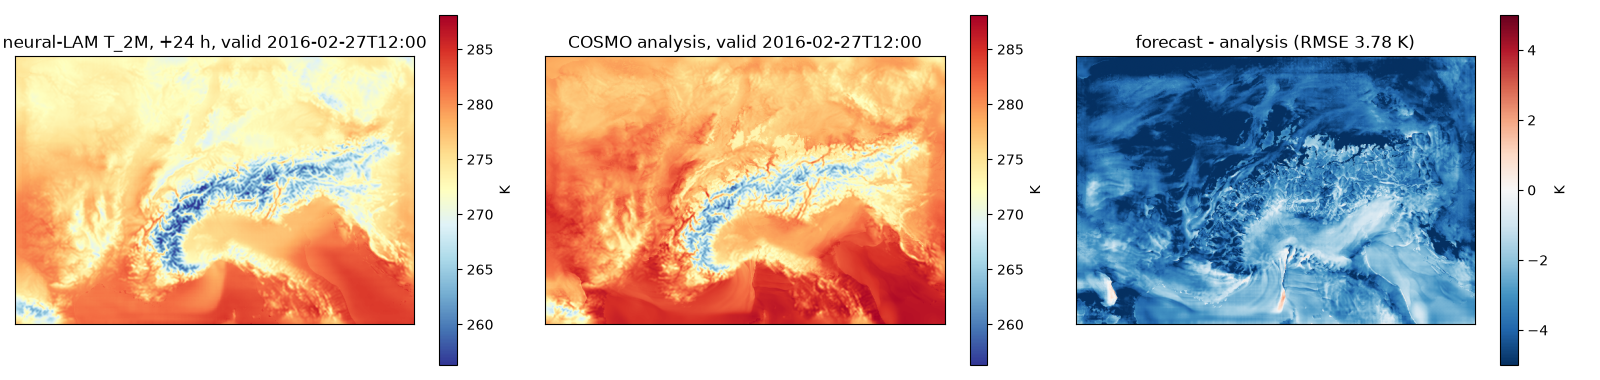

In [6]:
run_step(SCRIPT, "plot")
display(Image(str(WORKDIR / "sample_summary.png")))

## Next steps

- Full COSMO and DANRA reproduction: [docs/reproduce_paper.md](../docs/reproduce_paper.md).
- Every figure and table of the paper: [verification/README.md](../verification/README.md).
- Background on the COSMO data and its normalisation statistics: [docs/cosmo_dataset_reference.md](../docs/cosmo_dataset_reference.md).